Dataset Loaded Successfully!
Total Images: 1797
Input Shape: (1797, 64)
Training Images: 1437
Testing Images: 360

AUTOENCODER TRAINING STARTED
Epoch: 100 | MSE Loss: 0.073667
Epoch: 200 | MSE Loss: 0.073663
Epoch: 300 | MSE Loss: 0.073571
Epoch: 400 | MSE Loss: 0.054032
Epoch: 500 | MSE Loss: 0.045068

AUTOENCODER TRAINING COMPLETED!

COMPRESSED REPRESENTATION
Original Size: 64 values
Compressed Size: 8 values

Compressed Values:
[0.0246 0.9076 0.0764 0.1427 0.6137 0.1079 0.1836 0.8224]


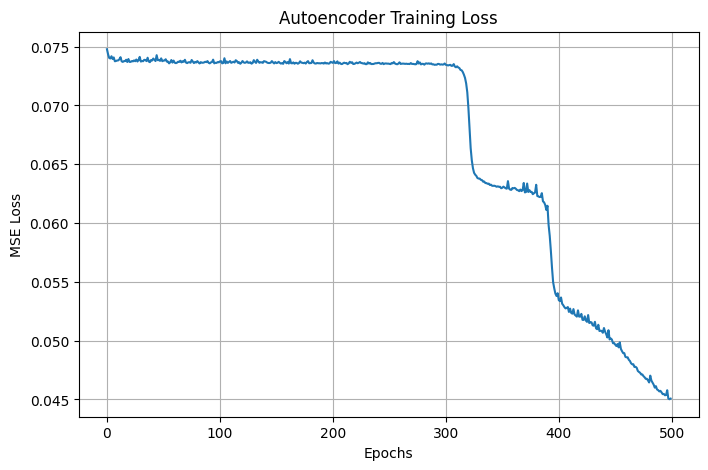

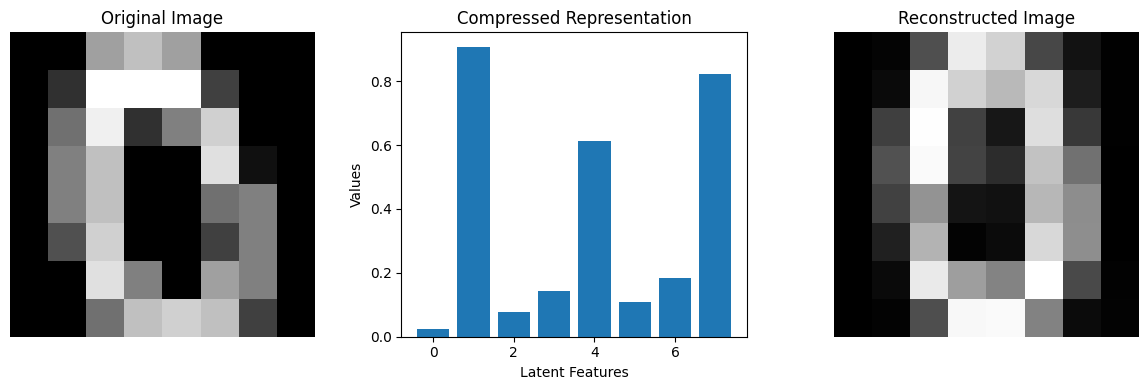


FINAL RESULT
Original Image Size: 64 values
Compressed Image Size: 8 values
Compression Ratio: 8.0 : 1
Reconstruction MSE: 0.03617158

Image Compression Completed Successfully!


In [ ]:
# DLL Experiment No. 6
# Autoencoder for Image Compression

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split


# 1. Load Predefined Dataset
data = load_digits()

X = data.images.reshape(-1, 64).astype(np.float32) / 16.0

print("Dataset Loaded Successfully!")
print("Total Images:", len(X))
print("Input Shape:", X.shape)


# 2. Split Dataset
X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))


# 3. Define Autoencoder Architecture
input_size = 64
hidden1_size = 32
hidden2_size = 16
compressed_size = 8

rng = np.random.default_rng(42)


# Xavier Weight Initialization
def initialize_weights(fan_in, fan_out):

    limit = np.sqrt(6 / (fan_in + fan_out))

    return rng.uniform(
        -limit, limit,
        (fan_in, fan_out)
    )


# Encoder Weights
W1 = initialize_weights(input_size, hidden1_size)
b1 = np.zeros((1, hidden1_size))

W2 = initialize_weights(hidden1_size, hidden2_size)
b2 = np.zeros((1, hidden2_size))

W3 = initialize_weights(hidden2_size, compressed_size)
b3 = np.zeros((1, compressed_size))


# Decoder Weights
W4 = initialize_weights(compressed_size, hidden2_size)
b4 = np.zeros((1, hidden2_size))

W5 = initialize_weights(hidden2_size, hidden1_size)
b5 = np.zeros((1, hidden1_size))

W6 = initialize_weights(hidden1_size, input_size)
b6 = np.zeros((1, input_size))


# 4. Activation Function
def sigmoid(x):

    x = np.clip(x, -50, 50)

    return 1 / (1 + np.exp(-x))


# Sigmoid Derivative
def sigmoid_derivative(x):

    return x * (1 - x)


# 5. Forward Propagation
def forward_propagation(X):

    # Encoder
    Z1 = np.dot(X, W1) + b1
    A1 = sigmoid(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)

    Z3 = np.dot(A2, W3) + b3
    compressed = sigmoid(Z3)

    # Decoder
    Z4 = np.dot(compressed, W4) + b4
    A4 = sigmoid(Z4)

    Z5 = np.dot(A4, W5) + b5
    A5 = sigmoid(Z5)

    Z6 = np.dot(A5, W6) + b6
    output = sigmoid(Z6)

    return A1, A2, compressed, A4, A5, output


# 6. Training Parameters
learning_rate = 0.5
epochs = 500
batch_size = 64

loss_history = []


# 7. Autoencoder Training
print("\n================================")
print("AUTOENCODER TRAINING STARTED")
print("================================")


for epoch in range(epochs):

    # Shuffle training samples
    indices = rng.permutation(len(X_train))

    for start in range(0, len(X_train), batch_size):

        batch_indices = indices[start:start + batch_size]

        X_batch = X_train[batch_indices]

        m = len(X_batch)


        # FORWARD PROPAGATION
        A1, A2, A3, A4, A5, output = forward_propagation(X_batch)


        # BACKPROPAGATION

        # Output Layer
        delta6 = (output - X_batch) * sigmoid_derivative(output) / m

        dW6 = np.dot(A5.T, delta6)
        db6 = np.sum(delta6, axis=0, keepdims=True)


        # Hidden Layer 5
        delta5 = np.dot(delta6, W6.T) * sigmoid_derivative(A5)

        dW5 = np.dot(A4.T, delta5)
        db5 = np.sum(delta5, axis=0, keepdims=True)


        # Hidden Layer 4
        delta4 = np.dot(delta5, W5.T) * sigmoid_derivative(A4)

        dW4 = np.dot(A3.T, delta4)
        db4 = np.sum(delta4, axis=0, keepdims=True)


        # Compressed Layer
        delta3 = np.dot(delta4, W4.T) * sigmoid_derivative(A3)

        dW3 = np.dot(A2.T, delta3)
        db3 = np.sum(delta3, axis=0, keepdims=True)


        # Hidden Layer 2
        delta2 = np.dot(delta3, W3.T) * sigmoid_derivative(A2)

        dW2 = np.dot(A1.T, delta2)
        db2 = np.sum(delta2, axis=0, keepdims=True)


        # Hidden Layer 1
        delta1 = np.dot(delta2, W2.T) * sigmoid_derivative(A1)

        dW1 = np.dot(X_batch.T, delta1)
        db1 = np.sum(delta1, axis=0, keepdims=True)


        # UPDATE WEIGHTS AND BIASES

        W6 -= learning_rate * dW6
        b6 -= learning_rate * db6

        W5 -= learning_rate * dW5
        b5 -= learning_rate * db5

        W4 -= learning_rate * dW4
        b4 -= learning_rate * db4

        W3 -= learning_rate * dW3
        b3 -= learning_rate * db3

        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1


    # Calculate Training Loss after each epoch
    _, _, _, _, _, train_output = forward_propagation(X_train)

    loss = np.mean((X_train - train_output) ** 2)

    loss_history.append(loss)


    # Display Progress
    if (epoch + 1) % 100 == 0:

        print(
            "Epoch:", epoch + 1,
            "| MSE Loss:", round(loss, 6)
        )


print("\nAUTOENCODER TRAINING COMPLETED!")


# 8. Select Random Test Image
sample_index = rng.integers(0, len(X_test))

original_image = X_test[sample_index].reshape(8, 8)


# 9. Compress Image
A1, A2, compressed, A4, A5, output = forward_propagation(
    X_test[sample_index:sample_index + 1]
)

compressed_representation = compressed[0]

print("\n================================")
print("COMPRESSED REPRESENTATION")
print("================================")

print("Original Size:", input_size, "values")
print("Compressed Size:", compressed_size, "values")

print("\nCompressed Values:")
print(np.round(compressed_representation, 4))


# 10. Reconstruct Image
reconstructed_image = output.reshape(8, 8)


# 11. Calculate Compression Ratio and MSE
compression_ratio = input_size / compressed_size

mse = np.mean(
    (original_image - reconstructed_image) ** 2
)


# 12. Display Training Loss
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.grid(True)
plt.show()


# 13. Display Original, Compressed and Reconstructed Images

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)

plt.imshow(original_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")


plt.subplot(1, 3, 2)

plt.bar(range(compressed_size), compressed_representation)

plt.title("Compressed Representation")
plt.xlabel("Latent Features")
plt.ylabel("Values")


plt.subplot(1, 3, 3)

plt.imshow(reconstructed_image, cmap="gray")
plt.title("Reconstructed Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# 14. Final Result
print("\n================================")
print("FINAL RESULT")
print("================================")

print("Original Image Size:", input_size, "values")

print("Compressed Image Size:", compressed_size, "values")

print("Compression Ratio:", round(compression_ratio, 2), ": 1")

print("Reconstruction MSE:", round(float(mse), 8))

print("\nImage Compression Completed Successfully!")

In [ ]:
# DLL Experiment No. 6
# Autoencoder for Image Compression

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files


# 1. Upload Image
uploaded = files.upload()

file_name = next(iter(uploaded))

print("Uploaded Image:", file_name)

img = Image.open(file_name).convert("RGB")

img = img.resize((32, 32))

image = np.array(img).astype(np.float32) / 255.0

# Display Original Image
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()


# 2. Flatten Image
X = image.reshape(1, 3072)

print("Original Image Size:", X.shape[1], "values")


# 3. Define Autoencoder Architecture
input_size = 3072
hidden1_size = 256
hidden2_size = 128
compressed_size = 64

rng = np.random.default_rng(42)


# Xavier Weight Initialization
def initialize_weights(fan_in, fan_out):

    limit = np.sqrt(6 / (fan_in + fan_out))

    return rng.uniform(
        -limit,
        limit,
        (fan_in, fan_out)
    )


# Encoder Weights
W1 = initialize_weights(input_size, hidden1_size)
b1 = np.zeros((1, hidden1_size))

W2 = initialize_weights(hidden1_size, hidden2_size)
b2 = np.zeros((1, hidden2_size))

W3 = initialize_weights(hidden2_size, compressed_size)
b3 = np.zeros((1, compressed_size))


# Decoder Weights
W4 = initialize_weights(compressed_size, hidden2_size)
b4 = np.zeros((1, hidden2_size))

W5 = initialize_weights(hidden2_size, hidden1_size)
b5 = np.zeros((1, hidden1_size))

W6 = initialize_weights(hidden1_size, input_size)
b6 = np.zeros((1, input_size))


# 4. Activation Function
def sigmoid(x):

    x = np.clip(x, -50, 50)

    return 1 / (1 + np.exp(-x))


# Sigmoid Derivative
def sigmoid_derivative(x):

    return x * (1 - x)


# 5. Training Parameters
learning_rate = 0.5
epochs = 5000

loss_history = []


# 6. Autoencoder Training
print("\nAutoencoder Training Started...")


for epoch in range(epochs):

    # FORWARD PROPAGATION

    # Encoder Layer 1
    Z1 = np.dot(X, W1) + b1
    A1 = sigmoid(Z1)

    # Encoder Layer 2
    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)

    # Compressed Layer
    Z3 = np.dot(A2, W3) + b3
    A3 = sigmoid(Z3)

    # Decoder Layer 1
    Z4 = np.dot(A3, W4) + b4
    A4 = sigmoid(Z4)

    # Decoder Layer 2
    Z5 = np.dot(A4, W5) + b5
    A5 = sigmoid(Z5)

    # Output Layer
    Z6 = np.dot(A5, W6) + b6
    output = sigmoid(Z6)


    # Calculate MSE Loss
    loss = np.mean((X - output) ** 2)

    loss_history.append(loss)


    # BACKPROPAGATION

    # Output Layer
    delta6 = (
        (output - X) *
        sigmoid_derivative(output)
    )

    dW6 = np.dot(A5.T, delta6)
    db6 = np.sum(delta6, axis=0, keepdims=True)


    # Decoder Layer 2
    delta5 = (
        np.dot(delta6, W6.T) *
        sigmoid_derivative(A5)
    )

    dW5 = np.dot(A4.T, delta5)
    db5 = np.sum(delta5, axis=0, keepdims=True)


    # Decoder Layer 1
    delta4 = (
        np.dot(delta5, W5.T) *
        sigmoid_derivative(A4)
    )

    dW4 = np.dot(A3.T, delta4)
    db4 = np.sum(delta4, axis=0, keepdims=True)


    # Compressed Layer
    delta3 = (
        np.dot(delta4, W4.T) *
        sigmoid_derivative(A3)
    )

    dW3 = np.dot(A2.T, delta3)
    db3 = np.sum(delta3, axis=0, keepdims=True)


    # Encoder Layer 2
    delta2 = (
        np.dot(delta3, W3.T) *
        sigmoid_derivative(A2)
    )

    dW2 = np.dot(A1.T, delta2)
    db2 = np.sum(delta2, axis=0, keepdims=True)


    # Encoder Layer 1
    delta1 = (
        np.dot(delta2, W2.T) *
        sigmoid_derivative(A1)
    )

    dW1 = np.dot(X.T, delta1)
    db1 = np.sum(delta1, axis=0, keepdims=True)


    # UPDATE WEIGHTS AND BIASES

    W6 -= learning_rate * dW6
    b6 -= learning_rate * db6

    W5 -= learning_rate * dW5
    b5 -= learning_rate * db5

    W4 -= learning_rate * dW4
    b4 -= learning_rate * db4

    W3 -= learning_rate * dW3
    b3 -= learning_rate * db3

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1


    # Display Training Progress
    if (epoch + 1) % 500 == 0:

        print(
            "Epoch:", epoch + 1,
            "| MSE Loss:", loss
        )


# 7. Generate Compressed Representation

Z1 = np.dot(X, W1) + b1
A1 = sigmoid(Z1)

Z2 = np.dot(A1, W2) + b2
A2 = sigmoid(Z2)

Z3 = np.dot(A2, W3) + b3

compressed = sigmoid(Z3)


# 8. Display Compressed Values
print("\n================================")
print("COMPRESSED REPRESENTATION")
print("================================")

print("Original Size:", input_size, "values")

print("Compressed Size:", compressed_size, "values")

print("\nCompressed Values:")
print(np.round(compressed[0], 4))


# 9. Reconstruct Image

Z4 = np.dot(compressed, W4) + b4
A4 = sigmoid(Z4)

Z5 = np.dot(A4, W5) + b5
A5 = sigmoid(Z5)

Z6 = np.dot(A5, W6) + b6

reconstructed = sigmoid(Z6)

reconstructed_image = reconstructed.reshape(32, 32, 3)


# 10. Calculate Compression Ratio and MSE

compression_ratio = input_size / compressed_size

mse = np.mean(
    (image - reconstructed_image) ** 2
)


# 11. Display Images

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(compressed.reshape(8, 8), cmap="viridis")
plt.title("Compressed Representation\n64 Values")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(np.clip(reconstructed_image, 0, 1))
plt.title("Reconstructed Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# 12. Loss Graph

plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.yscale("log")
plt.grid(True)
plt.show()


# 13. Final Results

print("\n================================")
print("FINAL RESULT")
print("================================")

print("Original Image Size:", "32 x 32 x 3")

print("Original Values:", input_size)

print("Compressed Values:", compressed_size)

print("Compression Ratio:", round(compression_ratio, 2), ": 1")

print("Reconstruction MSE:", round(float(mse), 8))

print("\nImage Compression Completed Successfully!")